# 05 Battery backtest
What would a hypothetical 100 MW / 200 MWh battery at Mt Roskill (matching Contact Energy's Glenbrook battery) have earned if it ran every day of the test year?

Each strategy **plans** the day's charge/discharge schedule with the LP using its price forecast, then is **paid at the actual prices**:
- **Perfect foresight**: plans with the actual prices (the upper bound)
- **Each forecasting model**: plans with that model's day-ahead forecast
- **Typical day**: plans with the median price for each trading period over all pre-test data (no forecast at all)

**Capture rate** = strategy profit / perfect-foresight profit × 100%.

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from battery import BATTERY, optimise_day, settle, day_profit
from forecasting import TEST_START, load_model_data

df = load_model_data()
test_preds = pd.read_parquet("../results/test_predictions.parquet")   # from notebook 04
test = df.loc[test_preds.index]                                       # actual test-year rows

## Check the LP on a toy day
Two cheap periods then two expensive ones: it should charge first, then discharge, and finish at 100 MWh.

In [2]:
toy_prices = np.array([20, 20, 300, 300])
charge, discharge, soc = optimise_day(toy_prices)

print(pd.DataFrame({"price": toy_prices,
                    "charge (MW)": charge,
                    "discharge (MW)": discharge,
                    "state of charge (MWh)": soc}).round(1))
print(f"Profit: ${settle(charge, discharge, toy_prices):,.0f}")

   price  charge (MW)  discharge (MW)  state of charge (MWh)
0     20        100.0             0.0                  147.0
1     20        100.0             0.0                  194.0
2    300          0.0            76.7                  153.2
3    300          0.0           100.0                  100.0
Profit: $24,066


In [3]:
# Only backtest days with all 48 periods (a day missing any forecast can't be scheduled)
full_day = test.groupby("date")["tp"].transform("size") == 48
test, test_preds = test[full_day], test_preds[full_day]
print(f"Days in the backtest: {test['date'].nunique()}")

# "Typical day": the median price of each trading period over all pre-test data
typical_day = df[df["date"] < TEST_START].groupby("tp")["price"].median()

# Every strategy's price forecast as a column: the 5 models + perfect foresight + typical day
strategies = test_preds.assign(**{
    "Perfect foresight": test["price"],
    "Typical day (no forecast)": test["tp"].map(typical_day),
})

Days in the backtest: 353


In [4]:
def daily_profits(forecast):
    """For one strategy: plan each day with its forecast, settle at actual prices.
    Returns one profit ($) per day."""
    table = pd.DataFrame({"forecast": forecast, "actual": test["price"], "date": test["date"]})
    return table.groupby("date").apply(lambda d: day_profit(d["forecast"], d["actual"]),
                                       include_groups=False)


# .apply runs daily_profits on each strategy column: one row per day, one column per strategy
profits = strategies.apply(daily_profits)
profits.to_parquet("../results/battery_daily_profits.parquet")

## Results from the test year

In [5]:
summary = pd.DataFrame({
    "Total profit ($m)": profits.sum() / 1e6,
    "Capture rate (%)": profits.sum() / profits["Perfect foresight"].sum() * 100,
}).sort_values("Total profit ($m)", ascending=False).round(2)
summary.to_csv("../results/battery_backtest.csv")
summary

,Total profit ($m),Capture rate (%)
Perfect foresight,8.94,100.00
Model 2a Linear (least squares),2.81,31.39
Model 2b Linear (absolute error),2.80,31.27
Model 3 LightGBM,2.68,29.93
Typical day (no forecast),2.63,29.46
Model 1 Weekly naive (last week),0.73,8.17
Model 0 Naive (yesterday),0.70,7.87


## What the optimal schedule looks like
The most profitable day of the test year, with perfect foresight.

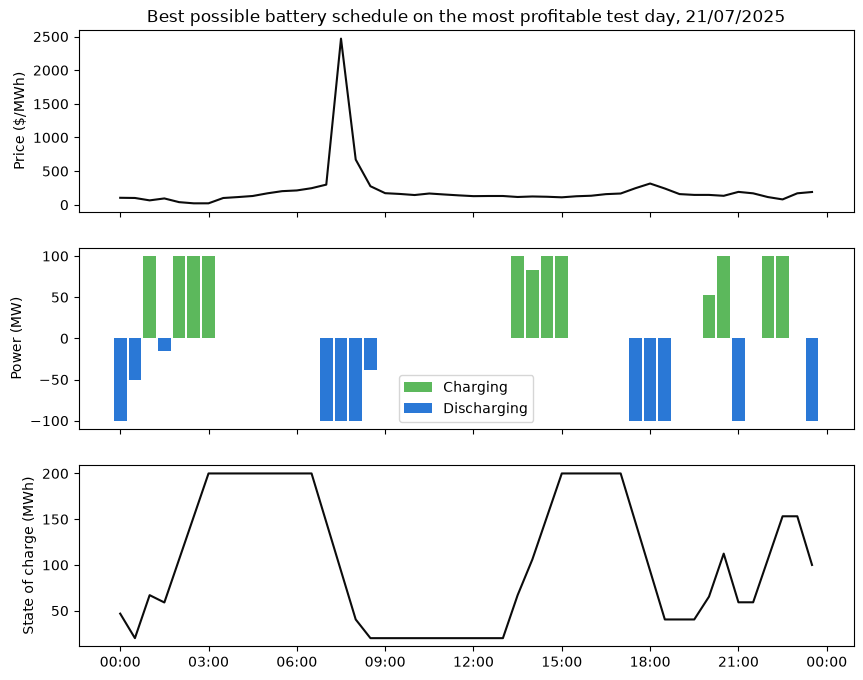

In [6]:
BLUE, GREEN, BLACK = "#2a78d6", "#5cb85c", "#0b0b0b"

DAY = profits["Perfect foresight"].idxmax()          # the most profitable test day
day = test[test["date"] == DAY]
charge, discharge, soc = optimise_day(day["price"])
times = day["time_nz"]

# Three stacked panels sharing the time axis: price, power, state of charge
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
ax1.plot(times, day["price"], color=BLACK, linewidth=1.5)
ax1.set_ylabel("Price ($/MWh)")
ax1.set_title(f"Best possible battery schedule on the most profitable test day, {pd.Timestamp(DAY).strftime('%d/%m/%Y')}")

ax2.bar(times, charge, width=0.018, color=GREEN, label="Charging")
ax2.bar(times, -discharge, width=0.018, color=BLUE, label="Discharging")
ax2.set_ylabel("Power (MW)")
ax2.legend()

ax3.plot(times, soc, color=BLACK, linewidth=1.5)
ax3.set_ylabel("State of charge (MWh)")
ax3.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=times.dt.tz))
fig.savefig("../results/figures/08_battery_schedule_day.png", dpi=150, bbox_inches="tight")

In [7]:
# How is the gap between perfect foresight and the best forecast spread across the year?
gap = (profits["Perfect foresight"] - profits["Model 2a Linear (least squares)"]).sort_values(ascending=False)
share = gap.cumsum() / gap.sum()          # running share of the total gap, biggest days first

print(f"Total gap: ${gap.sum() / 1e6:.2f}m")
print(f"Days making up half the gap: {(share < 0.5).sum() + 1}")
print(f"Share from the 10 worst days: {share.iloc[9]:.1%}")

Total gap: $6.13m
Days making up half the gap: 75
Share from the 10 worst days: 13.3%


## What are the key findings?
1. **Lowest forecast error is not equal to most profit.** LightGBM had the best MAE (\$30.22) but earned least of the trained models (\$2.68m, 29.9% capture). The linear models, which rank each day's prices best (Spearman 0.51 to 0.52), earned most (\$2.81m, 31.4%). **For battery scheduling, getting the order of prices right matters more than getting their level right.**
2. **About 70% of perfect-foresight profit (\$6.13m) is out of reach for the best forecast**, and the shortfall is spread across the year rather than concentrated in a few spikes. Half of it comes from 75 different days, and the 10 worst days account for only 13%. On the biggest spike day (21/07/2025, \$2,470/MWh) the linear forecast actually captured 90%.
3. **A "typical day" schedule with no forecast captured 29.5%**, only about 2 points behind the best model. Most of the achievable value comes from the predictable daily price shape, though forecasting becomes clearly more valuable when cycling is costly or lossy (see notebook 06).
4. **Naive forecasts captured only about 8%**, despite an MAE close to least squares. They lose money on 43% of days, because when yesterday's prices were flat the plan's timing is arbitrary and can charge straight into a spike (see notebook 06).
5. On the best day, the optimal schedule cycled **twice**, charging overnight and at midday, then discharging into the morning spike and evening peak.